In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

def get_input_path(filename):
    """Automatically resolves file path in Kaggle input datasets, working dir, or local directory."""
    if os.path.exists(filename):
        return filename
    for root, _, files in os.walk('/kaggle/input'):
        if filename in files:
            return os.path.join(root, filename)
    for root, _, files in os.walk('/kaggle/working'):
        if filename in files:
            return os.path.join(root, filename)
    return filename

df = pd.read_parquet(get_input_path('df_classification_2.parquet'))
df.head()

,date,time,client_id_x,amount,use_chip,merchant_city,merchant_state,mcc,errors,abs_amount,...,weekend_flag,account_age_years,years_since_pin_change,credit_limit_to_income,customer_avg_amount,customer_std_amount,customer_txn_count,amount_vs_avg,amount_zscore,transaction_datetime
1198,2010-01-01,13:10:00,0,33.959999,Swipe Transaction,Portland,ME,5942,None,33.959999,...,0,3,-4,0.295238,61.847805,79.603157,8646,0.549090,-0.350335,2010-01-01 13:10:00
2001,2010-01-01,19:39:00,0,7.780000,Swipe Transaction,Scarborough,ME,5812,None,7.780000,...,0,3,-4,0.295238,61.847805,79.603157,8646,0.125793,-0.679217,2010-01-01 19:39:00
2219,2010-01-01,22:13:00,0,65.860001,Swipe Transaction,Scarborough,ME,5813,None,65.860001,...,0,3,-4,0.295238,61.847805,79.603157,8646,1.064872,0.050402,2010-01-01 22:13:00
5855,2010-01-03,15:44:00,0,1.370000,Swipe Transaction,Scarborough,ME,5499,None,1.370000,...,1,3,-4,0.295238,61.847805,79.603157,8646,0.022151,-0.759741,2010-01-03 15:44:00
7055,2010-01-04,08:49:00,0,167.619995,Online Transaction,Online,None,4814,None,167.619995,...,0,3,-4,0.295238,61.847805,79.603157,8646,2.710201,1.328744,2010-01-04 08:49:00


In [3]:
import polars as pl

pl_df = pl.from_pandas(df[['client_id_x', 'transaction_datetime', 'abs_amount']])
pl_df = pl_df.sort(['client_id_x', 'transaction_datetime'])

pl_df = pl_df.rolling(
    index_column='transaction_datetime',
    period='24h',
    group_by='client_id_x'
).agg([
    (pl.len() - 1).alias('txn_count_last_24h'), #excluding the current transaction
    (pl.col('abs_amount').sum() - pl.col('abs_amount').last()).alias('amount_sum_last_24h'), #excluding the current transaction amount
])

In [4]:
df = df.merge(
    pl_df.to_pandas(),
    on=['client_id_x', 'transaction_datetime'],
    how='left'
)

In [1]:
df.shape

(8993227, 34)

In [5]:
df.head()

,date,time,client_id_x,amount,use_chip,merchant_city,merchant_state,mcc,errors,abs_amount,...,years_since_pin_change,credit_limit_to_income,customer_avg_amount,customer_std_amount,customer_txn_count,amount_vs_avg,amount_zscore,transaction_datetime,txn_count_last_24h,amount_sum_last_24h
0,2010-01-01,13:10:00,0,33.959999,Swipe Transaction,Portland,ME,5942,None,33.959999,...,-4,0.295238,61.847805,79.603157,8646,0.549090,-0.350335,2010-01-01 13:10:00,0,0.000000
1,2010-01-01,19:39:00,0,7.780000,Swipe Transaction,Scarborough,ME,5812,None,7.780000,...,-4,0.295238,61.847805,79.603157,8646,0.125793,-0.679217,2010-01-01 19:39:00,1,33.959999
2,2010-01-01,22:13:00,0,65.860001,Swipe Transaction,Scarborough,ME,5813,None,65.860001,...,-4,0.295238,61.847805,79.603157,8646,1.064872,0.050402,2010-01-01 22:13:00,2,41.739998
3,2010-01-03,15:44:00,0,1.370000,Swipe Transaction,Scarborough,ME,5499,None,1.370000,...,-4,0.295238,61.847805,79.603157,8646,0.022151,-0.759741,2010-01-03 15:44:00,0,0.000000
4,2010-01-04,08:49:00,0,167.619995,Online Transaction,Online,None,4814,None,167.619995,...,-4,0.295238,61.847805,79.603157,8646,2.710201,1.328744,2010-01-04 08:49:00,1,1.369995


In [6]:
dupes = df.duplicated(subset=['client_id_x', 'transaction_datetime']).sum()
print(dupes)

117100


In [7]:
dupes/df.shape[0]*100

np.float64(1.3020910069322167)

In [8]:
dupe_rows = df[df.duplicated(subset=['client_id_x', 'transaction_datetime'], keep=False)]
print(dupe_rows['target_numeric'].mean() * 100, "% fraud rate in duplicate-timestamp rows")

0.20174632648209662 % fraud rate in duplicate-timestamp rows


In [9]:
overall_error_rate = (df['errors'].notna().sum() / len(df)) * 100
print(f"Overall error rate: {overall_error_rate:.2f}%")

Overall error rate: 1.62%


In [10]:
dupe_rows = df[df.duplicated(subset=['client_id_x', 'transaction_datetime'], keep=False)]

dupe_error_rate = (dupe_rows['errors'].notna().sum() / len(dupe_rows)) * 100
print(f"Error rate in duplicate timestamp rows: {dupe_error_rate:.2f}%")

Error rate in duplicate timestamp rows: 5.50%


> ~1.3% of transactions shared identical timestamps with another transaction from the same client. These rows showed a somewhat higher error rate (5.5% vs 1.6% baseline), though the cause wasnt conclusively identified. So handled as a known data limitation.

In [11]:
dupe_rows_sorted = dupe_rows.sort_values(['client_id_x', 'transaction_datetime'])
dupe_rows_sorted['position_in_group'] = dupe_rows_sorted.groupby(
    ['client_id_x', 'transaction_datetime']
).cumcount()

error_by_position = dupe_rows_sorted.groupby('position_in_group')['errors'].apply(
    lambda x: x.notna().mean() * 100
)
print(error_by_position)

position_in_group
0     5.464311
1     5.464311
2     5.529177
3     5.531771
4     4.421769
5     4.421769
6     6.462585
7     6.462585
8     6.462585
9     0.000000
10    0.000000
11    0.000000
12    0.000000
13    0.000000
14    0.000000
15    0.000000
Name: errors, dtype: float64


In [12]:
pd.set_option('display.max_columns', None)

In [13]:
df.head()

,date,time,client_id_x,amount,use_chip,merchant_city,merchant_state,mcc,errors,abs_amount,target_numeric,current_age,gender,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards,card_brand,card_type,has_chip,num_cards_issued,credit_limit,debt_to_income,available_credit_per_card,hour,day_of_week,weekend_flag,account_age_years,years_since_pin_change,credit_limit_to_income,customer_avg_amount,customer_std_amount,customer_txn_count,amount_vs_avg,amount_zscore,transaction_datetime,txn_count_last_24h,amount_sum_last_24h
0,2010-01-01,13:10:00,0,33.959999,Swipe Transaction,Portland,ME,5942,None,33.959999,0.0,33,Male,29237.0,59613.0,36199.0,763,4,Mastercard,Credit,True,1,17600.0,0.607233,4400.0,13,4,0,3,-4,0.295238,61.847805,79.603157,8646,0.549090,-0.350335,2010-01-01 13:10:00,0,0.000000
1,2010-01-01,19:39:00,0,7.780000,Swipe Transaction,Scarborough,ME,5812,None,7.780000,0.0,33,Male,29237.0,59613.0,36199.0,763,4,Mastercard,Credit,True,1,17600.0,0.607233,4400.0,19,4,0,3,-4,0.295238,61.847805,79.603157,8646,0.125793,-0.679217,2010-01-01 19:39:00,1,33.959999
2,2010-01-01,22:13:00,0,65.860001,Swipe Transaction,Scarborough,ME,5813,None,65.860001,0.0,33,Male,29237.0,59613.0,36199.0,763,4,Mastercard,Credit,True,1,17600.0,0.607233,4400.0,22,4,0,3,-4,0.295238,61.847805,79.603157,8646,1.064872,0.050402,2010-01-01 22:13:00,2,41.739998
3,2010-01-03,15:44:00,0,1.370000,Swipe Transaction,Scarborough,ME,5499,None,1.370000,0.0,33,Male,29237.0,59613.0,36199.0,763,4,Mastercard,Credit,True,1,17600.0,0.607233,4400.0,15,6,1,3,-4,0.295238,61.847805,79.603157,8646,0.022151,-0.759741,2010-01-03 15:44:00,0,0.000000
4,2010-01-04,08:49:00,0,167.619995,Online Transaction,Online,None,4814,None,167.619995,0.0,33,Male,29237.0,59613.0,36199.0,763,4,Mastercard,Credit,True,1,17600.0,0.607233,4400.0,8,0,0,3,-4,0.295238,61.847805,79.603157,8646,2.710201,1.328744,2010-01-04 08:49:00,1,1.369995


In [14]:
df.shape

(8993227, 39)

In [15]:
df.isnull().sum().sort_values(ascending=False)

errors                       8847159
merchant_state               1051344
time                               0
client_id_x                        0
amount                             0
use_chip                           0
date                               0
merchant_city                      0
mcc                                0
abs_amount                         0
target_numeric                     0
current_age                        0
gender                             0
per_capita_income                  0
yearly_income                      0
total_debt                         0
credit_score                       0
num_credit_cards                   0
card_brand                         0
card_type                          0
has_chip                           0
num_cards_issued                   0
credit_limit                       0
debt_to_income                     0
available_credit_per_card          0
hour                               0
day_of_week                        0
w

In [16]:
df.columns

Index(['date', 'time', 'client_id_x', 'amount', 'use_chip', 'merchant_city',
       'merchant_state', 'mcc', 'errors', 'abs_amount', 'target_numeric',
       'current_age', 'gender', 'per_capita_income', 'yearly_income',
       'total_debt', 'credit_score', 'num_credit_cards', 'card_brand',
       'card_type', 'has_chip', 'num_cards_issued', 'credit_limit',
       'debt_to_income', 'available_credit_per_card', 'hour', 'day_of_week',
       'weekend_flag', 'account_age_years', 'years_since_pin_change',
       'credit_limit_to_income', 'customer_avg_amount', 'customer_std_amount',
       'customer_txn_count', 'amount_vs_avg', 'amount_zscore',
       'transaction_datetime', 'txn_count_last_24h', 'amount_sum_last_24h'],
      dtype='object')

In [17]:
df.drop(columns=['customer_avg_amount', 'customer_std_amount', 'customer_txn_count', 'amount_vs_avg', 'amount_zscore'], inplace=True)

In [2]:
df.to_parquet('classification_df_v2.parquet')

## Temporary Train Test Split

In [18]:
df = df.sort_values('transaction_datetime').reset_index(drop=True)

split_point = int(len(df) * 0.8)
split_date = df.iloc[split_point]['transaction_datetime']

train_df = df[df['transaction_datetime'] < split_date].copy()
test_df = df[df['transaction_datetime'] >= split_date].copy()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Train fraud rate:", train_df['target_numeric'].mean() * 100, "%")
print("Test fraud rate:", test_df['target_numeric'].mean() * 100, "%")
print("Train date range:", train_df['transaction_datetime'].min(), "to", train_df['transaction_datetime'].max())
print("Test date range:", test_df['transaction_datetime'].min(), "to", test_df['transaction_datetime'].max())

Train shape: (7194581, 34)
Test shape: (1798646, 34)
Train fraud rate: 0.14398336748171991 %
Test fraud rate: 0.1740197904423661 %
Train date range: 2010-01-01 00:01:00 to 2017-12-04 11:31:00
Test date range: 2017-12-04 11:32:00 to 2019-10-31 23:57:00


In [19]:
client_stats = train_df.groupby('client_id_x')['abs_amount'].agg(
    customer_avg_amount='mean',
    customer_std_amount='std',
    customer_txn_count='count'
)

train_df = train_df.merge(client_stats, on='client_id_x', how='left')
test_df = test_df.merge(client_stats, on='client_id_x', how='left')

In [20]:
global_avg = train_df['abs_amount'].mean()
global_std = train_df['abs_amount'].std()

for d in [train_df, test_df]:
    d['customer_avg_amount'] = d['customer_avg_amount'].fillna(global_avg)
    d['customer_std_amount'] = d['customer_std_amount'].fillna(global_std).replace(0, global_std)
    d['customer_txn_count'] = d['customer_txn_count'].fillna(0)
    d['amount_vs_avg'] = d['abs_amount'] / d['customer_avg_amount']
    d['amount_zscore'] = ((d['abs_amount'] - d['customer_avg_amount']) / d['customer_std_amount']).replace([np.inf, -np.inf], 0).fillna(0)

train_df['merchant_state'] = train_df['merchant_state'].fillna("Online")
test_df['merchant_state'] = test_df['merchant_state'].fillna("Online")

In [21]:
mcc_stats = train_df.groupby('mcc').agg(
    mcc_fraud_rate=('target_numeric', 'mean'),
    mcc_avg_amount=('abs_amount', 'mean'),
    mcc_txn_count=('mcc', 'size')
)

In [22]:
city_stats = train_df.groupby('merchant_city').agg(
    city_fraud_rate=('target_numeric', 'mean'),
    city_avg_amount=('abs_amount', 'mean'),
    city_txn_count=('merchant_city', 'size'),
    city_unique_customers=('client_id_x', 'nunique')
)

In [23]:
state_stats = train_df.groupby('merchant_state').agg(
    state_fraud_rate=('target_numeric', 'mean'),
    state_avg_amount=('abs_amount', 'mean'),
    state_txn_count=('merchant_state', 'size'),
    state_unique_customers=('client_id_x', 'nunique')
)

In [24]:
client_stats_fraud = train_df.groupby('client_id_x').agg(
    client_fraud_rate=('target_numeric', 'mean')
)

In [25]:
train_df = train_df.merge(mcc_stats, on='mcc', how='left')
train_df = train_df.merge(city_stats, on='merchant_city', how='left')
train_df = train_df.merge(state_stats, on='merchant_state', how='left')
train_df = train_df.merge(client_stats_fraud, on='client_id_x', how='left')

test_df = test_df.merge(mcc_stats, on='mcc', how='left')
test_df = test_df.merge(city_stats, on='merchant_city', how='left')
test_df = test_df.merge(state_stats, on='merchant_state', how='left')
test_df = test_df.merge(client_stats_fraud, on='client_id_x', how='left')

In [26]:
global_fraud_rate = train_df['target_numeric'].mean()
global_amount = train_df['abs_amount'].mean()

In [27]:
fraud_rate_cols = ['mcc_fraud_rate', 'city_fraud_rate', 'state_fraud_rate', 'client_fraud_rate']
amount_cols = ['mcc_avg_amount', 'city_avg_amount', 'state_avg_amount']
count_cols = ['mcc_txn_count', 'city_txn_count', 'state_txn_count', 'city_unique_customers', 'state_unique_customers']

for d in [train_df, test_df]:
    for col in fraud_rate_cols:
        d[col] = d[col].fillna(global_fraud_rate)
    for col in amount_cols:
        d[col] = d[col].fillna(global_amount)
    for col in count_cols:
        d[col] = d[col].fillna(0)

In [28]:
df.head(10)

,date,time,client_id_x,amount,use_chip,merchant_city,merchant_state,mcc,errors,abs_amount,target_numeric,current_age,gender,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards,card_brand,card_type,has_chip,num_cards_issued,credit_limit,debt_to_income,available_credit_per_card,hour,day_of_week,weekend_flag,account_age_years,years_since_pin_change,credit_limit_to_income,transaction_datetime,txn_count_last_24h,amount_sum_last_24h
0,2010-01-01,00:01:00,1556,-77.000000,Swipe Transaction,Beulah,ND,5499,None,77.000000,0.0,30,Female,23679.0,48277.0,110153.0,740,4,Mastercard,Debit (Prepaid),True,2,55.0,2.281687,13.750000,0,4,0,2,2,0.001139,2010-01-01 00:01:00,0,0.0
1,2010-01-01,00:02:00,1129,80.000000,Swipe Transaction,Vista,CA,4829,None,80.000000,0.0,49,Male,16894.0,34449.0,36540.0,686,3,Mastercard,Debit,True,1,14802.0,1.060698,4934.000000,0,4,0,4,2,0.429679,2010-01-01 00:02:00,0,0.0
2,2010-01-01,00:02:00,561,14.570000,Swipe Transaction,Bettendorf,IA,5311,None,14.570000,0.0,48,Male,18076.0,36853.0,112139.0,834,5,Mastercard,Credit,True,1,9100.0,3.042873,1820.000000,0,4,0,5,-5,0.246927,2010-01-01 00:02:00,0,0.0
3,2010-01-01,00:06:00,848,46.410000,Swipe Transaction,Harwood,MD,5813,None,46.410000,0.0,51,Male,33529.0,68362.0,96182.0,711,2,Visa,Debit,True,1,19113.0,1.406951,9556.500000,0,4,0,1,-4,0.279585,2010-01-01 00:06:00,0,0.0
4,2010-01-01,00:07:00,1807,4.810000,Swipe Transaction,Bronx,NY,5942,None,4.810000,0.0,47,Female,25537.0,52065.0,98613.0,828,5,Mastercard,Debit (Prepaid),True,1,89.0,1.894036,17.800000,0,4,0,2,-5,0.001709,2010-01-01 00:07:00,0,0.0
5,2010-01-01,00:14:00,1684,26.459999,Online Transaction,Online,None,4784,None,26.459999,0.0,56,Male,13668.0,27861.0,108313.0,782,5,Mastercard,Debit (Prepaid),True,1,46.0,3.887621,9.200000,0,4,0,3,-2,0.001651,2010-01-01 00:14:00,0,0.0
6,2010-01-01,00:23:00,554,3.510000,Swipe Transaction,Pearland,TX,5311,None,3.510000,0.0,59,Male,26170.0,53357.0,114266.0,690,5,Visa,Debit,False,1,25658.0,2.141537,5131.600000,0,4,0,1,1,0.480874,2010-01-01 00:23:00,0,0.0
7,2010-01-01,00:23:00,605,2.580000,Swipe Transaction,Brooklyn,NY,5411,None,2.580000,0.0,42,Male,23316.0,47542.0,2667.0,725,3,Visa,Debit,True,2,1484.0,0.056098,494.666667,0,4,0,4,-1,0.031215,2010-01-01 00:23:00,0,0.0
8,2010-01-01,00:26:00,1556,39.630001,Swipe Transaction,Beulah,ND,5499,None,39.630001,0.0,30,Female,23679.0,48277.0,110153.0,740,4,Mastercard,Debit (Prepaid),True,2,55.0,2.281687,13.750000,0,4,0,2,2,0.001139,2010-01-01 00:26:00,1,77.0
9,2010-01-01,00:27:00,1797,43.330002,Swipe Transaction,Kahului,HI,4121,None,43.330002,0.0,67,Male,24971.0,30962.0,15336.0,743,5,Visa,Debit,True,2,23237.0,0.495317,4647.400000,0,4,0,3,1,0.750501,2010-01-01 00:27:00,0,0.0


In [29]:
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

In [30]:

print(train_df['credit_score'].describe())
print(train_df['current_age'].describe())
print(train_df['credit_limit'].describe())
print(train_df['total_debt'].describe())

count   7194581.000
mean        713.860
std          65.823
min         488.000
25%         684.000
50%         716.000
75%         756.000
max         850.000
Name: credit_score, dtype: float64
count   7194581.000
mean         54.110
std          15.686
min          23.000
25%          42.000
50%          52.000
75%          63.000
max         101.000
Name: current_age, dtype: float64
count   7194581.000
mean      15524.900
std       12190.935
min           0.000
25%        8081.000
50%       13435.000
75%       20839.000
max      141391.000
Name: credit_limit, dtype: float64
count   7194581.000
mean      57977.648
std       51798.453
min           0.000
25%       16437.000
50%       51679.000
75%       85160.000
max      461854.000
Name: total_debt, dtype: float64


In [31]:
top_1pct_threshold = train_df['abs_amount'].quantile(0.99)
extreme_txns = train_df[train_df['abs_amount'] > top_1pct_threshold]
print(extreme_txns['target_numeric'].mean() * 100, "% fraud rate in top 1% amounts")
print(train_df['target_numeric'].mean() * 100, "% baseline fraud rate")

1.1890193024420093 % fraud rate in top 1% amounts
0.14398336748171991 % baseline fraud rate


In [32]:
print(train_df['debt_to_income'].describe())
print(train_df['credit_limit_to_income'].describe())

count   7194581.000
mean          1.236
std           0.880
min           0.000
25%           0.429
50%           1.282
75%           1.884
max           4.678
Name: debt_to_income, dtype: float64
count   7194581.000
mean          0.366
std           1.262
min           0.000
25%           0.216
50%           0.323
75%           0.459
max          81.000
Name: credit_limit_to_income, dtype: float64


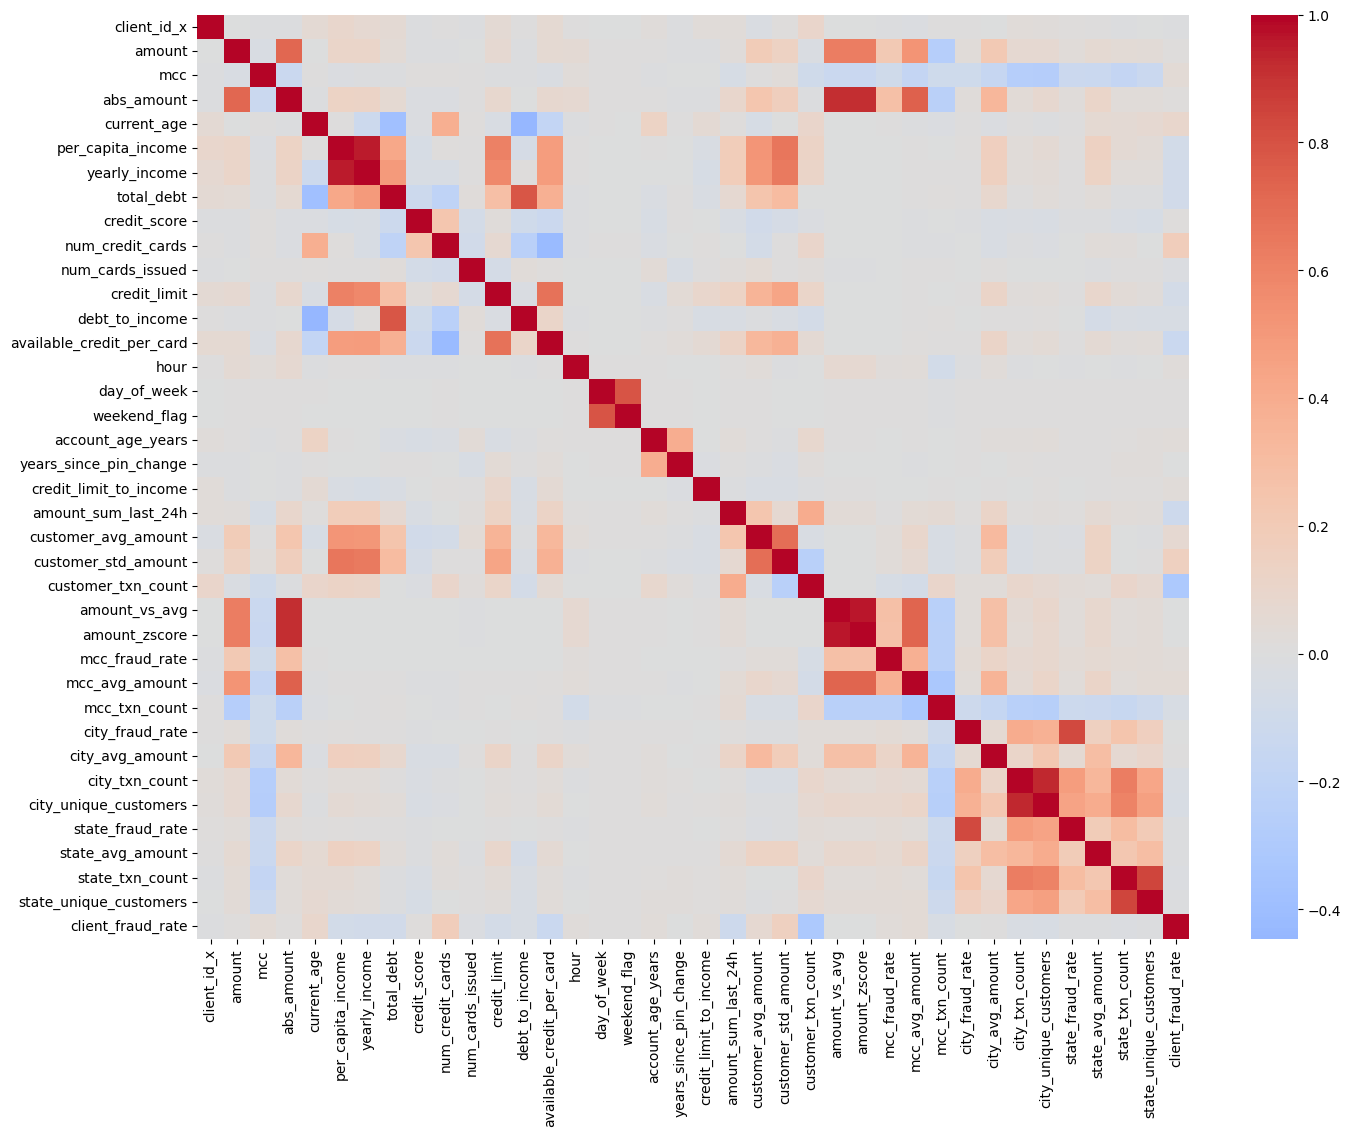

In [33]:
numeric_cols = train_df.select_dtypes(include=['int8','int16','int32','int64',
                                                  'float16','float32','float64']).columns
numeric_cols = [c for c in numeric_cols if c != 'target_numeric']

corr_matrix = train_df[numeric_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.show()

In [34]:
corr_matrix.loc[
    ['state_fraud_rate', 'city_fraud_rate', 'mcc_fraud_rate'],
    ['state_fraud_rate', 'city_fraud_rate', 'mcc_fraud_rate']
]

,state_fraud_rate,city_fraud_rate,mcc_fraud_rate
state_fraud_rate,1.000,0.830,0.044
city_fraud_rate,0.830,1.000,0.042
mcc_fraud_rate,0.044,0.042,1.000


In [35]:
threshold = 0.85
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i,j]
        if abs(val)>threshold:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], round(val, 3)))


high_corr_pairs    

[('abs_amount', 'amount_vs_avg', np.float64(0.912)),
 ('abs_amount', 'amount_zscore', np.float64(0.913)),
 ('per_capita_income', 'yearly_income', np.float64(0.949)),
 ('amount_vs_avg', 'amount_zscore', np.float64(0.965)),
 ('city_txn_count', 'city_unique_customers', np.float64(0.929))]

In [36]:
high_corr_df = pd.DataFrame(high_corr_pairs, columns = ['feature 1', 'feature 2', 'correlation'])
high_corr_df

,feature 1,feature 2,correlation
0,abs_amount,amount_vs_avg,0.912
1,abs_amount,amount_zscore,0.913
2,per_capita_income,yearly_income,0.949
3,amount_vs_avg,amount_zscore,0.965
4,city_txn_count,city_unique_customers,0.929


In [37]:
train_df.corr(numeric_only = True).loc[:, 'target_numeric']

client_id_x                 -0.000
amount                       0.035
mcc                         -0.015
abs_amount                   0.045
target_numeric               1.000
current_age                  0.004
per_capita_income           -0.003
yearly_income               -0.004
total_debt                  -0.004
credit_score                 0.001
num_credit_cards             0.007
has_chip                     0.001
num_cards_issued            -0.000
credit_limit                -0.006
debt_to_income              -0.002
available_credit_per_card   -0.007
hour                        -0.008
day_of_week                  0.007
weekend_flag                 0.006
account_age_years           -0.001
years_since_pin_change      -0.001
credit_limit_to_income      -0.001
txn_count_last_24h           0.019
amount_sum_last_24h          0.038
customer_avg_amount          0.003
customer_std_amount          0.006
customer_txn_count          -0.013
amount_vs_avg                0.053
amount_zscore       

In [38]:
train_df.drop(columns=['amount_vs_avg', 'per_capita_income', 'city_txn_count'], inplace=True)

In [39]:
test_df.drop(columns=['amount_vs_avg', 'per_capita_income', 'city_txn_count'], inplace=True)

- keeping amount_zscore since it gives one of the important information

In [40]:
cols_to_remove = ['amount_vs_avg', 'per_capita_income', 'city_txn_count']

numeric_cols = [col for col in numeric_cols if col not in cols_to_remove]

In [41]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = train_df[numeric_cols].dropna().sample(n=500_000, random_state=42)
vif_df = pd.DataFrame()
vif_df['feature'] = vif_data.columns
vif_df

,feature
0,client_id_x
1,amount
2,mcc
3,abs_amount
4,current_age
5,yearly_income
6,total_debt
7,credit_score
8,num_credit_cards
9,num_cards_issued


In [42]:
vif_df['VIF'] = [variance_inflation_factor(vif_data.values, i) for i in range(len(vif_data.columns))]

In [43]:
vif_df

,feature,VIF
0,client_id_x,4.207
1,amount,2.765
2,mcc,40.508
3,abs_amount,17.714
4,current_age,18.562
5,yearly_income,17.391
6,total_debt,14.922
7,credit_score,74.717
8,num_credit_cards,14.608
9,num_cards_issued,9.707


In [44]:
drop_cols = [
    'state_fraud_rate',       # redundant with city_fraud_rate (0.83 corr, weaker target corr)
    'state_avg_amount',       # VIF 55.7, redundant with city/mcc avg_amount
    'state_unique_customers', # VIF 30.6, redundant with city size features
    'mcc',                    # VIF 40.5, raw code redundant with mcc_fraud_rate/avg_amount/txn_count
    'customer_std_amount',    # VIF 28.0, redundant with customer_avg_amount
    'yearly_income',          # weak target corr + high VIF, redundant with ratios
    'total_debt',             # weak target corr + high VIF, redundant with ratios
    'credit_limit',           # weak target corr + high VIF, redundant with ratios
    'available_credit_per_card', # weak target corr + high VIF
    'credit_limit_to_income',    # keeping debt_to_income 
]

train_df = train_df.drop(columns=drop_cols)
test_df = test_df.drop(columns=drop_cols)

In [45]:
suspect_cols = ['current_age', 'credit_score', 'account_age_years', 'years_since_pin_change', 'num_credit_cards']
train_df[suspect_cols].corr()

,current_age,credit_score,account_age_years,years_since_pin_change,num_credit_cards
current_age,1.000,-0.019,0.132,0.003,0.388
credit_score,-0.019,1.000,-0.042,0.009,0.242
account_age_years,0.132,-0.042,1.000,0.393,-0.025
years_since_pin_change,0.003,0.009,0.393,1.000,-0.004
num_credit_cards,0.388,0.242,-0.025,-0.004,1.000


In [46]:
train_df = train_df.drop(columns=['credit_score', 'current_age'])
test_df = test_df.drop(columns=['credit_score', 'current_age'])

In [47]:
print(train_df.shape, test_df.shape)

(7194581, 36) (1798646, 36)


In [48]:
train_df.columns

Index(['date', 'time', 'client_id_x', 'amount', 'use_chip', 'merchant_city',
       'merchant_state', 'errors', 'abs_amount', 'target_numeric', 'gender',
       'num_credit_cards', 'card_brand', 'card_type', 'has_chip',
       'num_cards_issued', 'debt_to_income', 'hour', 'day_of_week',
       'weekend_flag', 'account_age_years', 'years_since_pin_change',
       'transaction_datetime', 'txn_count_last_24h', 'amount_sum_last_24h',
       'customer_avg_amount', 'customer_txn_count', 'amount_zscore',
       'mcc_fraud_rate', 'mcc_avg_amount', 'mcc_txn_count', 'city_fraud_rate',
       'city_avg_amount', 'city_unique_customers', 'state_txn_count',
       'client_fraud_rate'],
      dtype='object')

In [49]:
train_df.drop(columns=['client_id_x', 'date', 'time', 'transaction_datetime'], inplace=True)
test_df.drop(columns=['client_id_x', 'date', 'time', 'transaction_datetime'], inplace=True)

In [50]:
train_df.isna().sum()

amount                          0
use_chip                        0
merchant_city                   0
merchant_state                  0
errors                    7077704
abs_amount                      0
target_numeric                  0
gender                          0
num_credit_cards                0
card_brand                      0
card_type                       0
has_chip                        0
num_cards_issued                0
debt_to_income                  0
hour                            0
day_of_week                     0
weekend_flag                    0
account_age_years               0
years_since_pin_change          0
txn_count_last_24h              0
amount_sum_last_24h             0
customer_avg_amount             0
customer_txn_count              0
amount_zscore                   0
mcc_fraud_rate                  0
mcc_avg_amount                  0
mcc_txn_count                   0
city_fraud_rate                 0
city_avg_amount                 0
city_unique_cu

In [51]:
test_df.isna().sum()

amount                          0
use_chip                        0
merchant_city                   0
merchant_state                  0
errors                    1769455
abs_amount                      0
target_numeric                  0
gender                          0
num_credit_cards                0
card_brand                      0
card_type                       0
has_chip                        0
num_cards_issued                0
debt_to_income                  0
hour                            0
day_of_week                     0
weekend_flag                    0
account_age_years               0
years_since_pin_change          0
txn_count_last_24h              0
amount_sum_last_24h             0
customer_avg_amount             0
customer_txn_count              0
amount_zscore                   0
mcc_fraud_rate                  0
mcc_avg_amount                  0
mcc_txn_count                   0
city_fraud_rate                 0
city_avg_amount                 0
city_unique_cu

In [52]:
train_df['errors'] = train_df['errors'].fillna('No Error')
test_df['errors'] = test_df['errors'].fillna('No Error')

In [53]:
train_df['errors'].nunique()

23

In [54]:
train_df['errors'].value_counts()

errors
No Error                                               7077704
Insufficient Balance                                     72565
Bad PIN                                                  17654
Technical Glitch                                         14553
Bad Card Number                                           4256
Bad Expiration                                            3346
Bad CVV                                                   3345
Bad Zipcode                                                644
Bad PIN,Insufficient Balance                               155
Insufficient Balance,Technical Glitch                      137
Bad Card Number,Insufficient Balance                        41
Bad PIN,Technical Glitch                                    33
Bad CVV,Insufficient Balance                                32
Bad Expiration,Insufficient Balance                         28
Bad Card Number,Bad Expiration                              25
Bad Card Number,Bad CVV                         

In [55]:
error_counts = train_df['errors'].value_counts()

rare_errors = error_counts[error_counts < 100].index

train_df['errors'] = train_df['errors'].replace(
    rare_errors,
    'Other Error'
)

test_df['errors'] = test_df['errors'].replace(
    rare_errors,
    'Other Error'
)

In [56]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7194581 entries, 0 to 7194580
Data columns (total 32 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   amount                  float32
 1   use_chip                object 
 2   merchant_city           object 
 3   merchant_state          object 
 4   errors                  object 
 5   abs_amount              float32
 6   target_numeric          float64
 7   gender                  object 
 8   num_credit_cards        int8   
 9   card_brand              object 
 10  card_type               object 
 11  has_chip                bool   
 12  num_cards_issued        int64  
 13  debt_to_income          float32
 14  hour                    int32  
 15  day_of_week             int32  
 16  weekend_flag            int64  
 17  account_age_years       int32  
 18  years_since_pin_change  int64  
 19  txn_count_last_24h      uint32 
 20  amount_sum_last_24h     float32
 21  customer_avg_amount     float32

In [57]:
train_df['has_chip'] = train_df['has_chip'].astype(int)
test_df['has_chip'] = test_df['has_chip'].astype(int)

In [58]:
train_df['gender'] = train_df['gender'].map({
    'Male': 0,
    'Female': 1
})
test_df['gender'] = test_df['gender'].map({
    'Male': 0,
    'Female': 1
})

In [59]:
train_df['is_online'] = (train_df['merchant_city'] == 'Online').astype('int8')
test_df['is_online'] = (test_df['merchant_city'] == 'Online').astype('int8')

Is online col will be used since Online is an important info

In [60]:
train_df.drop(columns=['merchant_city', 'merchant_state'], inplace=True)
test_df.drop(columns=['merchant_city', 'merchant_state'], inplace=True)

In [61]:
train_df.nunique()

amount                      65605
use_chip                        3
errors                         11
abs_amount                  65067
target_numeric                  2
gender                          2
num_credit_cards                9
card_brand                      4
card_type                       3
has_chip                        2
num_cards_issued                3
debt_to_income               1155
hour                           24
day_of_week                     7
weekend_flag                    2
account_age_years              28
years_since_pin_change         26
txn_count_last_24h             25
amount_sum_last_24h        535378
customer_avg_amount          1219
customer_txn_count           1145
amount_zscore             3681237
mcc_fraud_rate                 99
mcc_avg_amount                109
mcc_txn_count                 108
city_fraud_rate               528
city_avg_amount             11572
city_unique_customers         212
state_txn_count               141
client_fraud_r

In [62]:
train_df.to_parquet('train_df.parquet')
test_df.to_parquet('test_df.parquet')

KeyboardInterrupt: 

## Train Test Splitting

In [64]:
y_train = train_df['target_numeric']
y_test  = test_df['target_numeric']

X_train = train_df.drop(
    columns=['target_numeric']
)

X_test = test_df.drop(
    columns=['target_numeric']
)

In [65]:
y_train.value_counts(normalize=True)*100

target_numeric
0.000   99.856
1.000    0.144
Name: proportion, dtype: float64

In [66]:
y_test.value_counts(normalize=True)*100

target_numeric
0.000   99.826
1.000    0.174
Name: proportion, dtype: float64

# Feature Selection

In [67]:
numerical_features = [
    'amount',
    'abs_amount',
    'debt_to_income',

    'hour',
    'day_of_week',

    'account_age_years',
    'years_since_pin_change',

    'txn_count_last_24h',
    'amount_sum_last_24h',

    'customer_avg_amount',
    'customer_txn_count',
    'amount_zscore',

    'mcc_fraud_rate',
    'mcc_avg_amount',
    'mcc_txn_count',

    'city_fraud_rate',
    'city_avg_amount',
    'city_unique_customers',

    'state_txn_count',

    'client_fraud_rate',

    'num_credit_cards',
    'num_cards_issued'
]
categorical_features = [
    'use_chip',
    'errors',
    'card_brand',
    'card_type'
]
binary_features = [
    'gender',
    'has_chip',
    'weekend_flag',
    'is_online'
]

In [68]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [69]:
numeric_transformer = Pipeline([
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

In [70]:
preprocessor_ohe = ColumnTransformer(transformers = [
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
], remainder='passthrough')

## 1. Random Forest Feature Importance

In [71]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor_ohe),
    ('rf', RandomForestClassifier(
        n_estimators=50,
        class_weight='balanced',
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   '...
                                                   'city_avg_amount',
                                                   'city_unique_customers',
                                                   'state_txn_count',
                                                   'client_fraud_rate',
                                                   'num_credit_cards',
                                                   'num_cards_issued']),
                                                 ('cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['use_chip', 'errors',
                                                   'card_brand',
                                                   'card_type'])])),
                ('rf',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        n_estimators=50, n_jobs=-1,
                                        random_state=42))])

In [74]:
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()
importances = rf_pipeline.named_steps['rf'].feature_importances_

In [75]:
f1_df = pd.DataFrame({'feature': feature_names,'importance': importances}).sort_values('importance',ascending=False)

In [76]:
f1_df

,feature,importance
15,num__city_fraud_rate,0.214
12,num__mcc_fraud_rate,0.120
23,cat__use_chip_Online Transaction,0.108
18,num__state_txn_count,0.106
46,remainder__is_online,0.072
17,num__city_unique_customers,0.071
16,num__city_avg_amount,0.067
14,num__mcc_txn_count,0.064
13,num__mcc_avg_amount,0.037
19,num__client_fraud_rate,0.027


## 2. XGBoost Feature Importance

In [82]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor_ohe),
    ('xgb', XGBClassifier(
        n_estimators = 100,
        max_depth = 10,
        tree_method = 'hist',
        n_jobs = -1,
        random_state = 42
    ) )
])
xgb_pipeline.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   '...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=10, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [83]:
xgb_pipeline.named_steps['xgb'].get_params()

{'objective': 'binary:logistic',
 'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': None,
 'device': None,
 'early_stopping_rounds': None,
 'enable_categorical': False,
 'eval_metric': None,
 'feature_types': None,
 'feature_weights': None,
 'gamma': None,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': None,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': 10,
 'max_leaves': None,
 'min_child_weight': None,
 'missing': nan,
 'monotone_constraints': None,
 'multi_strategy': None,
 'n_estimators': 100,
 'n_jobs': -1,
 'num_parallel_tree': None,
 'random_state': 42,
 'reg_alpha': None,
 'reg_lambda': None,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': None,
 'tree_method': 'hist',
 'validate_parameters': None,
 'verbosity': None}

In [84]:
feature_names = xgb_pipeline.named_steps['preprocessor'].get_feature_names_out()
importances = xgb_pipeline.named_steps['xgb'].feature_importances_

In [85]:
f2_df = pd.DataFrame({'feature':feature_names, 'importance': importances}).sort_values(by='importance', ascending=False)
f2_df

,feature,importance
19,num__client_fraud_rate,0.279
17,num__city_unique_customers,0.136
15,num__city_fraud_rate,0.134
12,num__mcc_fraud_rate,0.127
14,num__mcc_txn_count,0.087
13,num__mcc_avg_amount,0.057
18,num__state_txn_count,0.053
1,num__abs_amount,0.030
8,num__amount_sum_last_24h,0.019
11,num__amount_zscore,0.016


## Permutational Importance

In [77]:
rf_model = rf_pipeline.named_steps['rf']
preprocessor = rf_pipeline.named_steps['preprocessor']

In [78]:
X_test_processed = preprocessor.transform(X_test)

In [79]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_test_processed,
    y_test,
    n_repeats=5,
    random_state=42,
    n_jobs=-1, 
    scoring='average_precision'
)

In [80]:
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()

In [81]:
f3_df = pd.DataFrame({
    'feature': feature_names,
    'permutation_importance': perm.importances_mean
}).sort_values(by='permutation_importance', ascending=False)

f3_df

,feature,permutation_importance
15,num__city_fraud_rate,0.025
12,num__mcc_fraud_rate,0.011
16,num__city_avg_amount,0.005
13,num__mcc_avg_amount,0.005
14,num__mcc_txn_count,0.004
3,num__hour,0.003
17,num__city_unique_customers,0.003
0,num__amount,0.002
1,num__abs_amount,0.002
11,num__amount_zscore,0.001


In [86]:
f1_df['rf_rank'] = (
    f1_df['importance']
    .rank(method='dense', ascending=False)
)

f2_df['xgb_rank'] = (
    f2_df['importance']
    .rank(method='dense', ascending=False)
)

f3_df['perm_rank'] = (
    f3_df['permutation_importance']
    .rank(method='dense', ascending=False)
)

In [87]:
final_features_df = (
    f1_df[['feature', 'rf_rank']]
    .merge(
        f2_df[['feature', 'xgb_rank']],
        on='feature',
        how='outer'
    )
    .merge(
        f3_df[['feature', 'perm_rank']],
        on='feature',
        how='outer'
    )
)

In [88]:
final_features_df

,feature,rf_rank,xgb_rank,perm_rank
0,cat__card_brand_Amex,37.000,36.000,22.000
1,cat__card_brand_Discover,38.000,22.000,27.000
2,cat__card_brand_Mastercard,32.000,34.000,34.000
3,cat__card_brand_Visa,34.000,30.000,32.000
4,cat__card_type_Credit,28.000,29.000,17.000
5,cat__card_type_Debit,33.000,35.000,15.000
6,cat__card_type_Debit (Prepaid),26.000,17.000,19.000
7,cat__errors_Bad CVV,40.000,19.000,25.000
8,cat__errors_Bad Card Number,43.000,26.000,28.000
9,cat__errors_Bad Expiration,42.000,39.000,31.000


In [89]:
final_features_df['avg_rank'] = final_features_df[['rf_rank', 'xgb_rank', 'perm_rank']].mean(axis=1)
final_features_df = final_features_df.sort_values(by='avg_rank')

In [91]:
final_features_df

,feature,rf_rank,xgb_rank,perm_rank,avg_rank
27,num__city_fraud_rate,1.000,3.000,1.000,1.667
36,num__mcc_fraud_rate,2.000,4.000,2.000,2.667
28,num__city_unique_customers,6.000,2.000,7.000,5.000
37,num__mcc_txn_count,8.000,5.000,5.000,6.000
35,num__mcc_avg_amount,9.000,6.000,4.000,6.333
26,num__city_avg_amount,7.000,11.000,3.000,7.000
40,num__state_txn_count,4.000,7.000,11.000,7.333
21,num__abs_amount,13.000,8.000,9.000,10.000
25,num__amount_zscore,12.000,10.000,10.000,10.667
23,num__amount,14.000,12.000,8.000,11.333


In [ ]:
final_features_df
